# This is the report template for the Assignment in CSCU9M3 Autumn 2026

## Follow these instructions:
- Save this file in the form: __ZZZZZZZ_M3_Aut26_TheAssignment.ipynb__ where __ZZZZZZZ__ is your student number
- Fill in the report 
 * Use a mix of code and markdown cells to tell a data-story, only the *Executive Summary* should be contained in a single markdown cell
 * all other sections should have multiple cells and outputs, where you explain what you are doing and why.
- When you are finished then ...
 * Save the file
 * Restart the Kernel and re-run the whole notebook. "Kernel" -> "Restart & Run" in the menu at top
 * Make sure everything has executed as expected. If cells run with error that you want to keep to show your attempt, then manually run every cell below the faulty one to show the output.
 * Make sure no __Markdown__ cell is in *edit* mode
 * Save file again
 * Delete this cell and remove any instructions from the template (except headings)
 * __Download this notebook as HTML__, you do that under *File->Download as-> HTML*
   + make sure to use the same name format, just different extension
 * __Upload the html file__ to the assessment on Canvas and submit

## Executive Summary
Write a short (200 words max) summary of what the report contains and what you have discovered.

## Introduction
The World Bank's *Gender Statistics* database contains **991 indicators** for **265 economies** back to 1960.
It covers paid work, education, health, fertility, legal rights, financial inclusion and political
representation, and most indicators are published separately for women and for men.

I chose it for three reasons. Almost every indicator has a **female and a male version**, so the natural
unit of analysis is the *gap between women and men inside a country*. The data are a **panel**, so I can
study change over time rather than a single snapshot. And the topic is a global policy target: gender
equality is United Nations Sustainable Development Goal 5.

Going in, I expected gender gaps to be closing steadily as countries became richer and better educated, and
I suspected that girls' education would be the force closing the labour market gap. The report shows that
the first expectation is only partly true, and that the second is not supported by the data at all.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Data Cleaning
The zip file contains six CSV files. This notebook uses three of them:

| File | What it is | Why I need it |
|---|---|---|
| `Gender_StatsData.csv` | 262,615 rows of indicator values, one column per year (1960–2021) | the data itself |
| `Gender_StatsCountry.csv` | one row per economy: name, region, income group | to group countries and to spot regional aggregates |
| `Gender_StatsSeries.csv` | one row per indicator: definition, unit, source | to document the indicators |

The other three files (`...FootNote`, `...Country-Series`, `...Series-Time`) only contain notes about
where individual numbers came from. They are unuseful for the analysis, so I do not load them.

In [2]:
# a cheap look at the raw file (first 5 rows, all columns)
raw_peek = pd.read_csv("Gender_StatsData.csv", nrows=5)
print("Columns in the file:", raw_peek.shape[1])
raw_peek.iloc[0:4, 0:12]

Columns in the file: 67


,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,1966,1967
0,Africa Eastern and Southern,AFE,A woman can apply for a passport in the same w...,SG.APL.PSPT.EQ,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Africa Eastern and Southern,AFE,A woman can be head of household in the same w...,SG.HLD.HEAD.EQ,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Africa Eastern and Southern,AFE,A woman can choose where to live in the same w...,SG.LOC.LIVE.EQ,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Africa Eastern and Southern,AFE,A woman can get a job in the same way as a man...,SG.GET.JOBS.EQ,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


The layout is now clear: the first 4 columns identify *who* (country) and *what* (indicator), and the
remaining 62 columns are years, with one empty artefact column at the very end. Each row is therefore one (country, indicator) pair, and the years run
across the row. It's a **wide** layout, and is difficulty for analysis, because adding a new year means adding a new column and every calculation has to be repeated once per year.

follow from the raw_peek I make a practical decision **only keep the years 1990–2021.** The file has 67 columns. Before 1990 most of the modern indicators are empty, I only needs the years 1990–2021 and the four identifier columns It makes pandas read only 36 columns, which keeps the notebook fast and the memory use modest.

In [3]:
YEARS = [str(year) for year in range(1990, 2022)]   
ID_COLUMNS = ["Country Name", "Country Code", "Indicator Name", "Indicator Code"]

raw = pd.read_csv("Gender_StatsData.csv", usecols=ID_COLUMNS + YEARS)

print("Shape of the subset:", raw.shape)
print("Countries in the file:", raw["Country Code"].nunique())  #sum number of diffierent rows, avoid repetition
print("Indicators in the file:", raw["Indicator Code"].nunique())
raw.head(3)

Shape of the subset: (262615, 36)
Countries in the file: 265
Indicators in the file: 991


,Country Name,Country Code,Indicator Name,Indicator Code,1990,1991,1992,1993,1994,1995,...,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021
0,Africa Eastern and Southern,AFE,A woman can apply for a passport in the same w...,SG.APL.PSPT.EQ,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Africa Eastern and Southern,AFE,A woman can be head of household in the same w...,SG.HLD.HEAD.EQ,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Africa Eastern and Southern,AFE,A woman can choose where to live in the same w...,SG.LOC.LIVE.EQ,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
# only keep the two chosen indicators
INDICATORS = {    
"SL.TLF.CACT.FE.ZS": "Female labour force participation (% of women aged 15+)",    
"SL.TLF.CACT.MA.ZS": "Male labour force participation (% of men aged 15+)",
}
subset = raw[raw["Indicator Code"].isin(INDICATORS.keys())].copy()

print("Shape after filtering:", subset.shape)
print(subset["Indicator Code"].value_counts())

Shape after filtering: (530, 36)
Indicator Code
SL.TLF.CACT.FE.ZS    265
SL.TLF.CACT.MA.ZS    265
Name: count, dtype: int64


In [5]:
# reshape from wide to long format
long = subset.melt(
    id_vars=["Country Code", "Indicator Code"],   
    value_vars=YEARS,   # turn columns into rows
    var_name="Year",
    value_name="Value",
)
long["Year"] = long["Year"].astype(int)  #string to int
long["Value"] = pd.to_numeric(long["Value"], errors="coerce") 
long = long.dropna(subset=["Value"])  #delete empty value

print("Long shape:", long.shape)
long.head()

Long shape: (15040, 4)


,Country Code,Indicator Code,Year,Value
0,AFE,SL.TLF.CACT.FE.ZS,1990,64.888276
1,AFE,SL.TLF.CACT.MA.ZS,1990,80.220056
2,AFW,SL.TLF.CACT.FE.ZS,1990,60.038278
3,AFW,SL.TLF.CACT.MA.ZS,1990,72.574196
4,ARB,SL.TLF.CACT.FE.ZS,1990,19.427845


The next problem is **mixed units of observation**. The World Bank file places real countries and
aggregates such as "World", "Euro area" or "Sub-Saharan Africa" (which is an average of 48 countries) in
the same column. Averaging them together would double-count some countries and produce nonsense.

The country file gives a clean way to separate them: aggregates have **no region** ("Sub-Saharan Africa" is
in no region), while every real country belongs to one of seven regions. So I merge the metadata in and
drop the rows without a region. The same merge also brings in the *income group*, which I use later for
one of the descriptive questions.

In [6]:
#remove regional aggregates
country = pd.read_csv("Gender_StatsCountry.csv", usecols=["Country Code", "Short Name", "Region"])
print("economies in the country file:", len(country))

long = long.merge(country, on="Country Code", how="left")

# economies with no region are averages, not countries
aggregates = country.loc[country["Region"].isna(), "Country Code"].tolist()
print("regional averages to remove:", len(aggregates))

long = long[~long["Country Code"].isin(aggregates)]
print("rows left:", len(long), "| countries left:", long["Country Code"].nunique())

economies in the country file: 265
regional averages to remove: 48
rows left: 11968 | countries left: 187


In [7]:
# one row per country and year, plus the gap

data = long.pivot_table(index=["Country Code", "Year"],
                        columns="Indicator Code",
                        values="Value").reset_index()

data = data.merge(country, on="Country Code", how="left")

# men's rate minus women's rate 
data["LFPR_gap"] = data["SL.TLF.CACT.MA.ZS"] - data["SL.TLF.CACT.FE.ZS"]

print("shape:", data.shape)
data.dropna(subset=["LFPR_gap"]).head()      # only rows that really have data

shape: (5984, 7)


,Country Code,Year,SL.TLF.CACT.FE.ZS,SL.TLF.CACT.MA.ZS,Short Name,Region,LFPR_gap
0,AFG,1990,15.180,77.430000,Afghanistan,South Asia,62.250000
1,AFG,1991,15.214,77.176003,Afghanistan,South Asia,61.962003
2,AFG,1992,15.223,76.871002,Afghanistan,South Asia,61.648003
3,AFG,1993,15.197,76.580002,Afghanistan,South Asia,61.383002
4,AFG,1994,15.178,76.330002,Afghanistan,South Asia,61.152001


## Exploratory Data Analysis
Programmatically explore the dataset. Tell the reader, how the dataset looks like and at least three most interesting observations that you can learn from the data.

### Observation 1 — men's participation is high everywhere, women's is not

In 2019 women are in the labour force 51.4% of the time on average, men 70.9%. Men are in work almost
everywhere; the big differences between countries are all on the women's side.

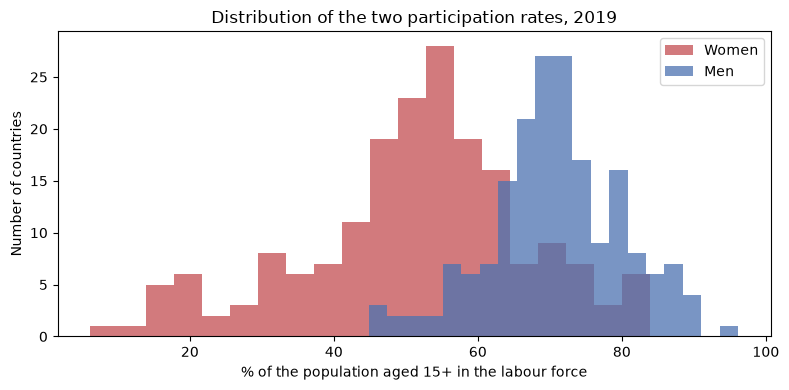

women: mean 51.4 %
men: mean 70.9 %


In [8]:
#the distribution of the two rates in 2019
data_2019 = data[data["Year"] == 2019].copy()
fig, ax = plt.subplots(figsize=(8, 4))

ax.hist(data_2019["SL.TLF.CACT.FE.ZS"], bins=20, color="#c44e52", alpha=0.75, label="Women")
ax.hist(data_2019["SL.TLF.CACT.MA.ZS"], bins=20, color="#4c72b0", alpha=0.75, label="Men")

ax.set_title("Distribution of the two participation rates, 2019")
ax.set_xlabel("% of the population aged 15+ in the labour force")
ax.set_ylabel("Number of countries")
ax.legend()
plt.tight_layout()
plt.show()
print("women: mean",round(data_2019["SL.TLF.CACT.FE.ZS"].mean(),1),"%")
print("men: mean",round(data_2019["SL.TLF.CACT.MA.ZS"].mean(),1),"%")

### Observation 2 — the global work gap is closing, but mostly because men's participation is falling

The world average gap fell from 26.7 points in 1990 to 19.5 points in 2019. The surprise is how it fell.
Women's participation barely moved (48.9% → 51.4%, +2.5 points), while men's participation fell by almost
twice as much (75.6% → 70.9%, −4.7 points). About **two thirds** of the improvement therefore comes from
men leaving the labour force, not from women entering it. The dip at the end of both lines is the first year
of COVID-19, which pulled both rates down and left the gap almost unchanged.

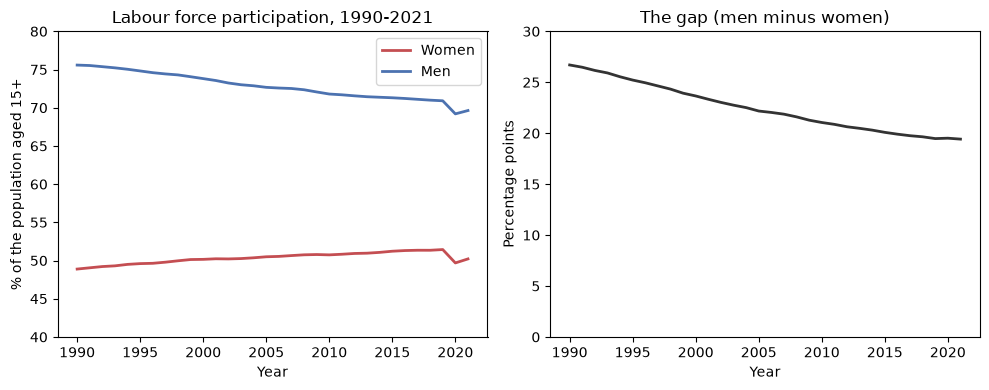

1990 -> 2019, women: 2.55 points
1990 -> 2019, men:   -4.68 points


In [9]:
global_trend = data.groupby("Year")[["SL.TLF.CACT.FE.ZS", "SL.TLF.CACT.MA.ZS", "LFPR_gap"]].mean()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

# left: the two rates over time
ax1.plot(global_trend.index, global_trend["SL.TLF.CACT.FE.ZS"], color="#c44e52", linewidth=2, label="Women")
ax1.plot(global_trend.index, global_trend["SL.TLF.CACT.MA.ZS"], color="#4c72b0", linewidth=2, label="Men")
ax1.set_title("Labour force participation, 1990-2021")
ax1.set_xlabel("Year")
ax1.set_ylabel("% of the population aged 15+")
ax1.set_ylim(40, 80)
ax1.legend()

# right: the gap between them
ax2.plot(global_trend.index, global_trend["LFPR_gap"], color="#333333", linewidth=2)
ax2.set_title("The gap (men minus women)")
ax2.set_xlabel("Year")
ax2.set_ylabel("Percentage points")
ax2.set_ylim(0, 30)

plt.tight_layout()
plt.show()

# how much of the change came from women and how much from men?
change_women = global_trend.loc[2019, "SL.TLF.CACT.FE.ZS"] - global_trend.loc[1990, "SL.TLF.CACT.FE.ZS"]
change_men = global_trend.loc[2019, "SL.TLF.CACT.MA.ZS"] - global_trend.loc[1990, "SL.TLF.CACT.MA.ZS"]
print("1990 -> 2019, women:", round(change_women, 2), "points")
print("1990 -> 2019, men:  ", round(change_men, 2), "points")

### Observation 3 — the gap exists in almost every country

The histogram shows how the gap is spread across countries in 1990 and in 2019. Almost all the bars are to
the right of zero: in **183 of the 187 countries** in 2019, more men than women are in the labour force. Only
four countries have a negative gap (Burundi, Rwanda, Guinea and Sierra Leone), and in all four the difference
is smaller than 2.5 points. The whole distribution moved left since 1990 — the median gap fell from 23.5 to
15.6 points — but the shape is the same. A gender gap in paid work is the normal case, not the exception.

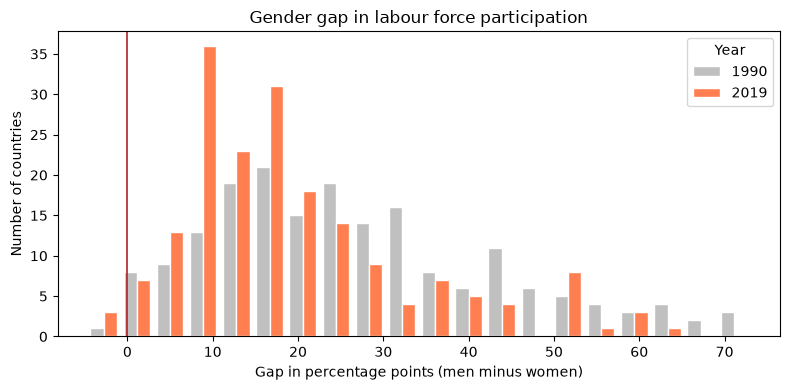

countries with data in 2019: 187
countries where women work more than men: 4
median gap 1990: 23.5 points
median gap 2019: 15.6 points


In [28]:
#the distribution of the gap, 1990 vs 2019
gap_1990 = data.loc[data["Year"] == 1990, "LFPR_gap"].dropna()
gap_2019 = data.loc[data["Year"] == 2019, "LFPR_gap"].dropna()

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist([gap_1990, gap_2019], bins=20, color=["#C0C0C0", "#FF7F50"],
        label=["1990", "2019"], edgecolor="white")
ax.axvline(0, color="#B22222", linewidth=1.2)      # the line "no gap"

ax.set_title("Gender gap in labour force participation")
ax.set_xlabel("Gap in percentage points (men minus women)")
ax.set_ylabel("Number of countries")
ax.legend(title="Year")
plt.tight_layout()
plt.show()

print("countries with data in 2019:", len(gap_2019))
print("countries where women work more than men:", (gap_2019 < 0).sum())
print("median gap 1990:", round(gap_1990.median(), 1), "points")
print("median gap 2019:", round(gap_2019.median(), 1), "points")

## Descriptive Analytics

### Question 1 — Which world regions have the widest gap?

**Why this is interesting.** A world average hides where the problem is worst. If the gap were the same
everywhere, it would look like a fixed feature of labour markets; if it varies a lot between regions, then
something about institutions, norms or the type of economy must matter.

In [41]:
q1 = data_2019.groupby("Region")[["SL.TLF.CACT.FE.ZS", "SL.TLF.CACT.MA.ZS", "LFPR_gap"]].mean().round(1)
q1.columns = ["Women (%)", "Men (%)", "Gap (points)"]
q1 = q1.sort_values("Gap (points)", ascending=False)
print(q1)

min_row = q1.loc[q1["Gap (points)"].idxmin()]
print("\nRegion:", min_row.name, " | Widest Gap (points):", min_row["Gap (points)"])

                            Women (%)  Men (%)  Gap (points)
Region                                                      
Middle East & North Africa       29.0     72.9          43.9
South Asia                       38.1     74.8          36.7
Latin America & Caribbean        51.5     73.8          22.3
East Asia & Pacific              57.6     73.0          15.4
Europe & Central Asia            51.7     65.8          14.1
Sub-Saharan Africa               59.3     71.5          12.3
North America                    59.0     69.1          10.0

Region: North America  | Widest Gap (points): 10.0


**Answer.** The gap ranges from **10.0 points in North America** and **12.3 points in Sub-Saharan Africa**
to **36.7 points in South Asia** and **43.9 points in the Middle East and North Africa** — a factor of four
between the most equal and the least equal region.

The ordering is also not what I expected: the richest region (North America) has the smallest gap, but
Sub-Saharan Africa, which is much poorer, has a smaller gap than Europe and Central Asia. Income alone does
not explain the pattern.

### Question 2 — Has the gap narrowed since 1990, and where?

**Why this is interesting.** The world average fell by 7 points, but averages can hide two opposite stories:
some regions may be catching up quickly while others stand still. Comparing 1990 with 2019 shows which
regions are actually changing.

                            1990  2019  Change
Region                                        
Latin America & Caribbean   33.9  22.3   -11.6
Middle East & North Africa  53.9  43.9   -10.0
South Asia                  46.7  36.7   -10.0
North America               18.0  10.0    -8.0
Europe & Central Asia       20.4  14.1    -6.3
East Asia & Pacific         20.4  15.4    -5.0
Sub-Saharan Africa          17.3  12.3    -5.0


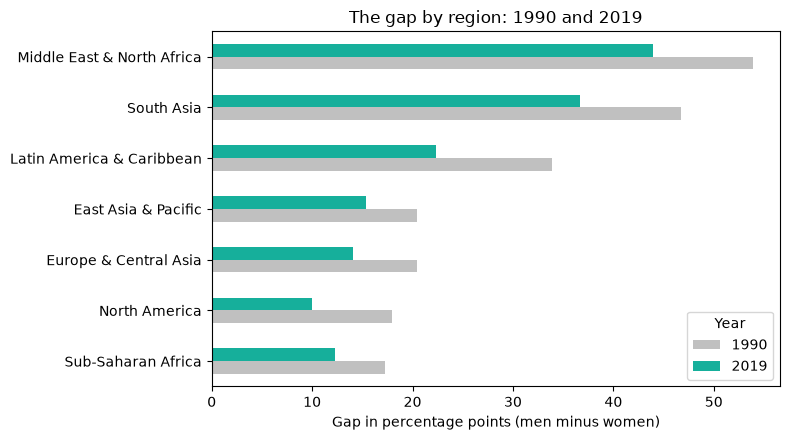

In [45]:
two_years = data[data["Year"].isin([1990, 2019])]

q2 = two_years.pivot_table(index="Region", columns="Year",
                           values="LFPR_gap", aggfunc="mean").round(1)
q2.columns = ["1990", "2019"]
q2["Change"] = (q2["2019"] - q2["1990"]).round(1)
q2 = q2.sort_values("Change")
print(q2)

# the same numbers as a chart
q2[["1990", "2019"]].sort_values("1990").plot(kind="barh", figsize=(8, 4.5),
                                             color=["#C0C0C0", "#16AF9B"])
plt.title("The gap by region: 1990 and 2019")
plt.xlabel("Gap in percentage points (men minus women)")
plt.ylabel("")
plt.legend(title="Year")
plt.tight_layout()
plt.show()

**Answer.** Yes, gap has declined in every region since 1990. The biggest reductions are in **Latin
America and the Caribbean (-11.6 points)**. The smallest reductions are in **East Asia and the Pacific (−5.0)** and **Sub-Saharan Africa(−5.0)**.

### Question 3 — Is the gap caused by women working less, or by men working more?

**Why this is interesting.** A gap of 20 points can be built in two very different ways: a country where
women work 50% of the time and men 70%, or a country where women work 20% and men 40%. The first is a small
difference in a working society; the second is a very different situation. Knowing which one is typical tells
us what kind of policy would help.

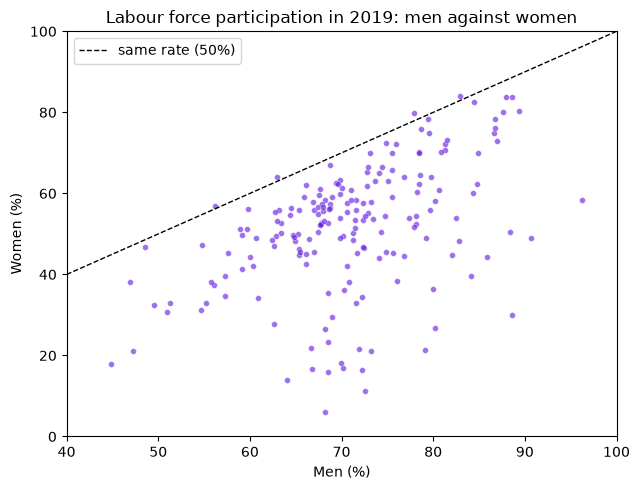

men:   mean 70.9 | standard deviation 9.2 | minimum 44.8
women: mean 51.4 | standard deviation 15.8 | minimum 6.1
countries where women work more than men: 4 of 187


In [47]:
q3 = data_2019.dropna(subset=["SL.TLF.CACT.FE.ZS", "SL.TLF.CACT.MA.ZS"])

fig, ax = plt.subplots(figsize=(6.5, 5))
ax.scatter(q3["SL.TLF.CACT.MA.ZS"], q3["SL.TLF.CACT.FE.ZS"],
           s=18, alpha=0.6, color="#5E13E0", edgecolor="white", linewidth=0.4)
ax.plot([40, 100], [40, 100], linestyle="--", color="black", linewidth=1, label="same rate (50%)")

ax.set_title("Labour force participation in 2019: men against women")
ax.set_xlabel("Men (%)")
ax.set_ylabel("Women (%)")
ax.set_xlim(40, 100)
ax.set_ylim(0, 100)
ax.legend()
plt.tight_layout()
plt.show()

print("men:   mean", round(q3["SL.TLF.CACT.MA.ZS"].mean(), 1),
      "| standard deviation", round(q3["SL.TLF.CACT.MA.ZS"].std(), 1),
      "| minimum", round(q3["SL.TLF.CACT.MA.ZS"].min(), 1))
print("women: mean", round(q3["SL.TLF.CACT.FE.ZS"].mean(), 1),
      "| standard deviation", round(q3["SL.TLF.CACT.FE.ZS"].std(), 1),
      "| minimum", round(q3["SL.TLF.CACT.FE.ZS"].min(), 1))
print("countries where women work more than men:",
      (q3["LFPR_gap"] < 0).sum(), "of", len(q3))


**Answer.** The gap is caused by **women working less**, not by men working more. Almost every points sit below the same rate line, women's participation rate is strictly lower than men's. The gender gap is nearly universal. 

## Suggestions
Suggest further steps to enrich the dataset with additional (external) data, or apply some additional advanced modelling or analysis. You do not have to fully implement your suggestions, but you will have to explain and justify your suggestions.

## Bibliography
List all sources you have utilised in the making of this report here.

In [ ]:
Zuizhinan(2026) https://zuizhinan.com/tools/color-codes/ — the color code.